# Week 7 — From meaning to measurement

This notebook follows the eight Python examples in the Week 7 course page, in teaching order. Run cells from top to bottom. The short questions after each example are for checking your understanding; change an input and rerun the cell to see what changes.

**Source:** `data/week7/Week 7 · From meaning to measurement · 02805.html`. The examples are retained from that page; the data loader, name filter, and small plot are added so the examples can run together in one notebook.


## Before you start

Use a Python Jupyter kernel. In a terminal connected to the **same Python environment** as the kernel, install the packages:

```bash
python -m pip install numpy scikit-learn matplotlib torch transformers sentence-transformers bertopic umap-learn spacy networkx
python -m spacy download en_core_web_sm
```

Download `marvel_pages.zip` from the [course data page](https://sunelehmann.com/socialgraphs2026-web/data/#loading) and put it at `data/marvel_pages.zip` relative to the repository root. If you keep it elsewhere, change `ZIP_PATH` below. The first run of each pretrained model downloads model weights, so allow time and an internet connection. The BERT and sentiment examples can run before you download the Marvel archive; the corpus examples need it.


## 1. A word changes with its context

A static word embedding would use one vector for **bank** everywhere. BERT gives each token a representation influenced by its sentence. This example extracts the vector for `bank` from three sentences and compares cosine similarity. The printed values are illustrative and can vary slightly with model versions.


In [6]:
from transformers import AutoTokenizer, AutoModel
import torch, numpy as np

tokenizer = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained("bert-base-uncased")

sentences = ["I went to the bank to deposit money.",
             "I sat on the river bank near the water.",
             "The bank approved the loan this morning."]

def vector_of(word, sentence):
    enc = tokenizer(sentence, return_tensors="pt")
    with torch.no_grad():
        hidden = bert(**enc).last_hidden_state[0]      # one vector per token
    tokens = tokenizer.convert_ids_to_tokens(enc["input_ids"][0])
    return hidden[tokens.index(word)].numpy()

money, river, loan = (vector_of("bank", s) for s in sentences)
cos = lambda a, b: a @ b / (np.linalg.norm(a) * np.linalg.norm(b))
print(f'HERE IS THE RESULT: {round(cos(money, river), 2)}, {round(cos(money, loan), 2)}')
# 0.48 0.81


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


HERE IS THE RESULT: 0.47999998927116394, 0.8100000023841858


**Try it:** Replace `bank` with another ambiguous word in three short sentences. The tokenizer must contain that word as a single token for `tokens.index(word)` to work; inspect `tokens` inside the function if it does not.


## 2. Load the Marvel corpus

The course examples assume a dictionary called `marvel_pages`, mapping each page name to its full text. The Week 7 page does not specify the archive layout, so this loader assumes one UTF-8 `.txt` file per page. It prints the count and sample names: check those before continuing. The course example uses 303 pages.


In [7]:
from pathlib import Path
from zipfile import ZipFile

ZIP_PATH = Path("data/marvel_pages.zip")  # relative to this notebook in notebooks/
if not ZIP_PATH.is_file():
    raise FileNotFoundError(f"Download marvel_pages.zip and place it at {ZIP_PATH.resolve()}")

with ZipFile(ZIP_PATH) as archive:
    members = [name for name in archive.namelist()
               if name.lower().endswith(".txt") and not name.startswith("__MACOSX/")]
    if not members:
        raise ValueError("No .txt pages found in the archive; inspect its file names and adapt this loader.")
    marvel_pages = {Path(name).stem: archive.read(name).decode("utf-8-sig")
                    for name in members}

print(f"Loaded {len(marvel_pages)} pages; sample names: {list(marvel_pages)[:5]}")


Loaded 304 pages; sample names: ['README', 'Abomination_(character)', 'Adam_Warlock', 'Agent_X_(Marvel_Comics)', 'Ajak']


## 3. One vector per page, then a 2D map

`all-MiniLM-L6-v2` returns 384-dimensional vectors. PCA and t-SNE each make a two-dimensional view of them. First, follow the course's **direct** `model.encode(texts)` example. Inspect `model.max_seq_length`: long pages are truncated, so these first vectors represent only the beginning of each page.


In [8]:
from sentence_transformers import SentenceTransformer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

names = list(marvel_pages)
texts = [marvel_pages[n] for n in names]          # one string per document

model = SentenceTransformer("all-MiniLM-L6-v2")
print(model.max_seq_length)
# 256

embeddings = model.encode(texts, normalize_embeddings=True)   # 303 × 384

pca_xy = PCA(n_components=2, random_state=42).fit_transform(embeddings)
tsne_xy = TSNE(n_components=2, perplexity=30, init="pca",
               learning_rate="auto", random_state=42).fit_transform(embeddings)


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

256


The coordinates are for visualization; distances in a 2D projection can differ from similarities in the original 384-dimensional space. This small plot makes the two projections visible.


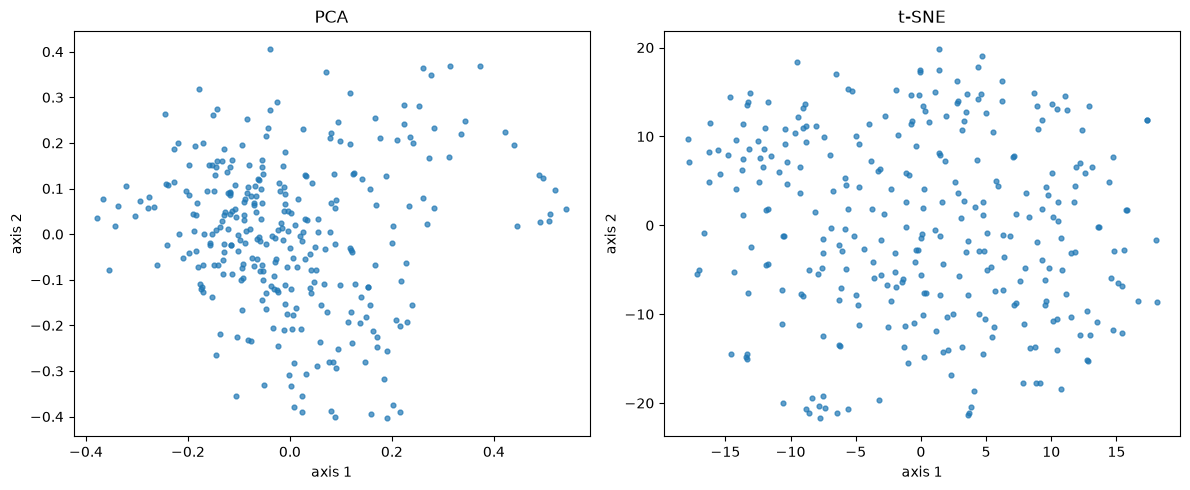

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, xy, title in zip(axes, (pca_xy, tsne_xy), ("PCA", "t-SNE")):
    ax.scatter(xy[:, 0], xy[:, 1], s=12, alpha=0.7)
    ax.set_title(title)
    ax.set_xlabel("axis 1")
    ax.set_ylabel("axis 2")
plt.tight_layout()
plt.show()

### A less truncated page representation

The next course example cuts each page into passages at sentence boundaries, embeds every passage, averages those vectors, and normalizes the result. It replaces `embeddings`, so the topic and search examples below use these page-wide vectors. The plot above still shows the earlier, truncated vectors; rerun the projection cell after this cell if you want a map of the passage-averaged vectors.


In [10]:
import re
import numpy as np

def passages(text, max_words=180):
    out, current, n = [], [], 0
    for sentence in re.split(r"(?<=[.!?])\s+", text):
        words = len(sentence.split())
        if current and n + words > max_words:
            out.append(" ".join(current)); current, n = [], 0
        current.append(sentence); n += words
    if current:
        out.append(" ".join(current))
    return out

doc_vectors = []
for text in texts:
    chunk_vectors = model.encode(passages(text), normalize_embeddings=True)
    v = chunk_vectors.mean(axis=0)
    doc_vectors.append(v / np.linalg.norm(v))
embeddings = np.array(doc_vectors)                # 4,473 passages → 303 vectors


**Check:** Compare the number of pages with `embeddings.shape[0]`, then inspect `passages(texts[0])[:2]`. Averaging passage vectors is one modeling choice; a page's beginning alone and its full collection of passages can give different neighbors.


In [13]:
embeddings.shape[0], passages(texts[0])[:2]

(304,
 ['02805 shared playground - week 5 release (frozen snapshot, 2026-08-26)\nFull plain-text Wikipedia article for each of the 303 characters in\nCategory:Marvel Comics superheroes - the same 303 nodes as week1_nodes.tsv. One file per character. The filename is the node_id, URL-encoded, because a\nfew titles contain characters a filesystem will not take (Mark_Hazzard%3A_Merc). urllib.parse.unquote the stem and it matches node_id exactly - see the loading\nsnippet on the course data page. '])

## 4. Group pages with BERTopic

The course example reuses `model`, `texts`, and the passage-averaged `embeddings`. It also assumes `proper`, a set of mostly capitalized words from Week 6, to keep character names out of topic keywords. The next cell supplies a simple corpus-based approximation. It is a heuristic: inspect its contents before interpreting topics.


In [14]:
from collections import Counter

word_counts = Counter()
capitalized_counts = Counter()
for text in texts:
    for word in re.findall(r"[A-Za-z]+", text):
        key = word.lower()
        word_counts[key] += 1
        if word[0].isupper():
            capitalized_counts[key] += 1

proper = {word for word, count in word_counts.items()
          if count >= 3 and capitalized_counts[word] / count >= 0.8}
print(f"Name-filter candidates: {len(proper)}; sample: {sorted(proper)[:20]}")


Name-filter candidates: 0; sample: []


In [15]:
from bertopic import BERTopic
from umap import UMAP
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS

topic_model = BERTopic(
    embedding_model=model,
    umap_model=UMAP(n_neighbors=15, n_components=5, min_dist=0.0,
                    metric="cosine", random_state=42),      # seeded, so the run repeats
    vectorizer_model=CountVectorizer(stop_words=list(ENGLISH_STOP_WORDS | proper)),
    min_topic_size=10,
)
topics, probs = topic_model.fit_transform(texts, embeddings=embeddings)
topic_model.get_topic_info()


,Topic,Count,Name,Representation,Representative_Docs
0,-1,100,-1_marvel_character_avengers_rider,"[marvel, character, avengers, rider, ghost, se...","[Ghost Rider (Johnathon ""Johnny"" Blaze) is a f..."
1,0,111,0_marvel_hulk_character_avengers,"[marvel, hulk, character, avengers, appears, m...",[The Hulk is a superhero appearing in American...
2,1,39,1_spider_man_venom_marvel,"[spider, man, venom, marvel, peter, symbiote, ...","[Spider-Girl (May ""Mayday"" Parker) is a superh..."
3,2,32,2_men_jean_phoenix_wolverine,"[men, jean, phoenix, wolverine, frost, betsy, ...",[Emma Grace Frost is a character appearing in ...
4,3,22,3_captain_america_britain_bucky,"[captain, america, britain, bucky, agent, walk...",[Jack Monroe is a fictional superhero appearin...


Topic `-1` means BERTopic treated those pages as outliers. `get_topic_info()` shows topic sizes and representative words; read some pages in each topic before assigning it a name. Results may differ from the course page because the name filter above is an approximation and clustering depends on package versions.


## 5. Sentiment is a measurement to validate

This movie-review classifier returns a label and confidence for each sentence. Compare ordinary praise, negation, sarcasm, and a story sentence. A high score tells you how confidently this model chose a label; it does not establish that the label measures the meaning you care about.


In [20]:
from transformers import pipeline

sentiment = pipeline(
    "sentiment-analysis",
    model="distilbert-base-uncased-finetuned-sst-2-english"
)

sentiment([
    "The movie was not bad.",
    "The movie was not good.",
    "I just love being stuck in traffic.",
    "The hero died, but saved everyone in the city.",
])
# [{'label': 'POSITIVE', 'score': 1.000}, {'label': 'NEGATIVE', 'score': 1.000},
#  {'label': 'POSITIVE', 'score': 0.998}, {'label': 'POSITIVE', 'score': 0.999}]


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[{'label': 'POSITIVE', 'score': 0.9987061023712158},
 {'label': 'NEGATIVE', 'score': 0.9997732043266296},
 {'label': 'POSITIVE', 'score': 0.9975196719169617},
 {'label': 'POSITIVE', 'score': 0.9993870258331299}]

**Try it:** Change only one word at a time (`good` → `bad`, add `not`, or add a sarcastic context). Keep a small table of inputs and outputs. The displayed numbers in the source are examples, not guaranteed values.


## 6. Find named entities, then connect co-mentioned names

spaCy assigns entity boundary tags to tokens (`B` starts an entity, `I` continues it, `O` is outside) and gives complete entity spans. The model can misclassify superhero names; compare its labels with your own reading before counting them.


In [21]:
import spacy

nlp = spacy.load("en_core_web_sm")
doc = nlp("Iron Man (Tony Stark) met Black Widow in New York.")

[(t.text, t.ent_iob_, t.ent_type_) for t in doc]
# [('Iron', 'O', ''), ('Man', 'O', ''), ('(', 'O', ''),
#  ('Tony', 'B', 'PERSON'), ('Stark', 'I', 'PERSON'), (')', 'O', ''),
#  ('met', 'O', ''), ('Black', 'B', 'ORG'), ('Widow', 'I', 'ORG'),
#  ('in', 'O', ''), ('New', 'B', 'GPE'), ('York', 'I', 'GPE'), ('.', 'O', '')]

[(e.text, e.label_) for e in doc.ents]
# [('Tony Stark', 'PERSON'), ('Black Widow', 'ORG'), ('New York', 'GPE')]


[('Tony Stark', 'PERSON'), ('Black Widow', 'ORG'), ('New York', 'GPE')]

The next course example counts pairs of recognized **PERSON** spans that appear in the same sentence of the Spider-Man page. An edge means co-mention in this code, not friendship or an interaction. `Tony Stark`, `Iron Man`, and `Stark` remain separate strings unless you explicitly resolve them.


In [22]:
from collections import Counter
import networkx as nx

page = nlp(marvel_pages["Spider-Man"])
pairs = Counter()
for sentence in page.sents:
    people = sorted({e.text for e in sentence.ents if e.label_ == "PERSON"})
    for i in range(len(people)):
        for j in range(i + 1, len(people)):
            pairs[(people[i], people[j])] += 1

G = nx.Graph()
for (a, b), weight in pairs.items():
    G.add_edge(a, b, weight=weight)
pairs.most_common(4)
# [(('Mary Jane', 'Peter'), 15), (('Peter Parker', 'Spider-Man'), 14),
#  (('Peter', 'Spider-Man'), 9), (('Ditko', 'Lee'), 8)]


[(('Mary Jane', 'Peter'), 15),
 (('Peter Parker', 'Spider-Man'), 14),
 (('Peter', 'Spider-Man'), 9),
 (('Ditko', 'Lee'), 8)]

**Check:** Inspect `pairs.most_common(4)` and a few source sentences. Which apparent links are caused by entity-label errors or by multiple names for the same character?


## 7. Search by words and by meaning

TF-IDF rewards word overlap. The dense retriever compares the query with the passage-averaged page embeddings. Both rank every page, even when the right answer is absent, so read the returned pages and judge relevance yourself.


In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

query = "a Russian spy who became an Avenger"

tfidf = TfidfVectorizer()
X = tfidf.fit_transform(texts)
sparse = (X @ tfidf.transform([query]).T).toarray().ravel()

q = model.encode(query, normalize_embeddings=True)
dense = embeddings @ q

for scores in (sparse, dense):
    top = np.argsort(-scores)[:4]
    print([(names[i], round(float(scores[i]), 2)) for i in top])
# [('Ursa Major (character)', 0.07), ('Black Widow (Natasha Romanova)', 0.06), ('Red Guardian', 0.05), ('Yelena Belova', 0.05)]
# [('Red Guardian', 0.61), ('U.S. Agent', 0.49), ('Ursa Major (character)', 0.47), ('Quicksilver (Marvel Comics)', 0.47)]


**Try it:** Test an exact-name query, a paraphrase with few shared words, and a query whose answer is absent. Compare both top-four lists. Because `embeddings` now comes from passages while the source's illustrative scores may have been made with a different representation, do not expect identical rankings.

### What to remember

- A representation is shaped by context, truncation, and how document parts are combined.
- A 2D map and a topic label are summaries that need checks against original text.
- Sentiment and named entities are model outputs; validation and entity resolution are separate steps.
- Retrieval scores rank candidates. Read the candidates before treating them as answers.
